**ARCHIVED HISTORICAL KERAS WORKFLOW — not part of the current application or supported setup.**
# Train U-Net for LGG MRI Segmentation
# Educational/research only — not for clinical diagnosis.
# Select Runtime → Change runtime type → GPU, then run all cells. Upload your Kaggle API token only when prompted; never publish it.

In [1]:
import numpy as np
import fastapi
import uvicorn
import pydantic
import tensorflow as tf

print(f"NumPy version: {np.__version__}")
print(f"FastAPI version: {fastapi.__version__}")
print(f"Uvicorn version: {uvicorn.__version__}")
print(f"Pydantic version: {pydantic.__version__}")
print(f"TensorFlow version: {tf.__version__}")

!pip install --upgrade --no-build-isolation kaggle scikit-learn
import os, shutil
from pathlib import Path
import tensorflow as tf

NumPy version: 2.1.3
FastAPI version: 0.141.1
Uvicorn version: 0.54.0
Pydantic version: 2.14.1
TensorFlow version: 2.21.0


In [2]:
## 1. Authenticate and download dataset

from google.colab import files
uploaded=files.upload()
if "kaggle.json" not in uploaded:
    raise RuntimeError("Upload the Kaggle API token file named kaggle.json.")
os.makedirs("/root/.kaggle",exist_ok=True)
shutil.copy("kaggle.json","/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json",0o600)
os.remove("kaggle.json")
!kaggle datasets download -d mateuszbuda/lgg-mri-segmentation -p /content/data --unzip

from google.colab import drive
drive.mount('/content/drive')

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation
License(s): CC-BY-NC-SA-4.0
100% 714M/714M [00:04<00:00, 166MB/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
## 2. Locate the patient folders

mask_files=list(Path("/content/data").rglob("*_mask.*"))
if not mask_files: raise FileNotFoundError("No *_mask.* files found. Inspect the Kaggle extraction and set DATA_DIR manually.")
DATA_DIR=str(mask_files[0].parent.parent)
print("Initial DATA_DIR:",DATA_DIR)
print("Example masks:",[str(p) for p in mask_files[:5]])

Initial DATA_DIR: /content/data/lgg-mri-segmentation/kaggle_3m
Example masks: ['/content/data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8167_19970402/TCGA_DU_8167_19970402_2_mask.tif', '/content/data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8167_19970402/TCGA_DU_8167_19970402_31_mask.tif', '/content/data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8167_19970402/TCGA_DU_8167_19970402_4_mask.tif', '/content/data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8167_19970402/TCGA_DU_8167_19970402_29_mask.tif', '/content/data/lgg-mri-segmentation/kaggle_3m/TCGA_DU_8167_19970402/TCGA_DU_8167_19970402_34_mask.tif']


In [ ]:
## 3. Write training script and train baseline/improved models

train_code = '''import argparse, json, random
from pathlib import Path
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
EXTS={".tif",".tiff",".png",".jpg",".jpeg"}

def collect_pairs(root):
    pairs=[]
    for m in sorted(Path(root).rglob("*_mask.*")):
        if m.suffix.lower() not in EXTS: continue
        image=m.with_name(m.name[:-len("_mask"+m.suffix)]+m.suffix)
        if image.exists(): pairs.append((str(image),str(m),m.parent.name))
    if not pairs: raise FileNotFoundError(f"No image/mask pairs under {root}; expected image.tif and image_mask.tif in patient folders.")
    return pairs

def split_groups(pairs):
    groups=np.array([p[2] for p in pairs]); ids=np.arange(len(pairs))
    tr,tmp=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(ids,groups=groups))
    va_rel,te_rel=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED+1).split(tmp,groups=groups[tmp]))
    return tr,tmp[va_rel],tmp[te_rel]

def load_pil(x,y,size):
    x=x.decode(); y=y.decode()
    with Image.open(x) as im: a=np.asarray(im.convert("RGB").resize((size,size),Image.Resampling.BILINEAR),np.float32)/255.
    with Image.open(y) as im: b=(np.asarray(im.convert("L").resize((size,size),Image.Resampling.NEAREST))>0).astype(np.float32)[...,None]
    return a,b

def load_pair(x,y,size):
    a,b=tf.numpy_function(lambda xx,yy:load_pil(xx,yy,size),[x,y],[tf.float32,tf.float32])
    a.set_shape([size,size,3]); b.set_shape([size,size,1]); return a,b

def augment_train_data(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    rotations = tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, rotations)
    mask = tf.image.rot90(mask, rotations)

    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)

    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, mask

def dataset(pairs, size, batch, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices(([p[0] for p in pairs], [p[1] for p in pairs]))
    if shuffle: ds = ds.shuffle(min(len(pairs), 2048), seed=SEED)
    ds = ds.map(lambda x, y: load_pair(x, y, size), num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_train_data, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

def dice(y,p,s=1.):
    y=tf.cast(y,tf.float32); p=tf.cast(p>.5,tf.float32)
    i=tf.reduce_sum(y*p,[1,2,3]); d=tf.reduce_sum(y,[1,2,3])+tf.reduce_sum(p,[1,2,3])
    return tf.reduce_mean((2*i+s)/(d+s))

def iou(y,p,s=1.):
    y=tf.cast(y,tf.float32); p=tf.cast(p>.5,tf.float32)
    i=tf.reduce_sum(y*p,[1,2,3]); u=tf.reduce_sum(y+p,[1,2,3])-i
    return tf.reduce_mean((i+s)/(u+s))

def loss_fn(y,p):
    bce=tf.reduce_mean(tf.keras.losses.binary_crossentropy(y,p))
    y=tf.reshape(tf.cast(y,tf.float32),[-1]); p=tf.reshape(tf.cast(p,tf.float32),[-1])
    i=tf.reduce_sum(y*p)
    return bce+1-(2*i+1)/(tf.reduce_sum(y)+tf.reduce_sum(p)+1)

def block(x,n):
    for _ in range(2):
        x=tf.keras.layers.Conv2D(n,3,padding="same",kernel_initializer="he_normal")(x)
        x=tf.keras.layers.BatchNormalization()(x); x=tf.keras.layers.Activation("relu")(x)
    return x

def residual_block(input_tensor, num_filters):
    x = tf.keras.layers.Conv2D(num_filters, (3, 3), padding='same', kernel_initializer="he_normal")(input_tensor)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(num_filters, (3, 3), padding='same', kernel_initializer="he_normal")(x)
    x = tf.keras.layers.BatchNormalization()(x)

    s = tf.keras.layers.Conv2D(num_filters, (1, 1), padding='same', kernel_initializer="he_normal")(input_tensor)
    x = tf.keras.layers.Add()([x, s])
    x = tf.keras.layers.Activation('relu')(x)
    return x

def attention_gate(f, g, num_filters):
    theta_f = tf.keras.layers.Conv2D(num_filters, (1, 1), strides=(1, 1), padding='same')(f)
    phi_g = tf.keras.layers.Conv2D(num_filters, (1, 1), strides=(1, 1), padding='same')(g)
    add_fg = tf.keras.layers.Activation('relu')(tf.keras.layers.Add()([theta_f, phi_g]))
    psi = tf.keras.layers.Conv2D(1, (1, 1), strides=(1, 1), padding='same')(add_fg)
    psi = tf.keras.layers.Activation('sigmoid')(psi)
    return tf.keras.layers.Multiply()([f, psi])

def build_unet(s):
    inp=tf.keras.Input((s,s,3)); skips=[]; x=inp
    for n in [16,32,64,128]:
        x=block(x,n); skips.append(x); x=tf.keras.layers.MaxPooling2D()(x)
    x=block(x,256)
    for n,skip in zip([128,64,32,16],reversed(skips)):
        x=tf.keras.layers.Conv2DTranspose(n,2,strides=2,padding="same")(x)
        x=tf.keras.layers.Concatenate()([x,skip]); x=block(x,n)
    out=tf.keras.layers.Conv2D(1,1,activation="sigmoid")(x)
    m=tf.keras.Model(inp,out,name="Standard_UNet"); return m

def build_attention_unet(s, num_filters=32):
    inputs = tf.keras.Input((s, s, 3))
    c1 = block(inputs, num_filters)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)
    c2 = block(p1, num_filters * 2)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)
    c3 = block(p2, num_filters * 4)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

    bn = block(p3, num_filters * 8)

    u3 = tf.keras.layers.UpSampling2D((2, 2))(bn)
    att3 = attention_gate(c3, u3, num_filters * 4)
    u3 = tf.keras.layers.Concatenate()([u3, att3])
    c4 = block(u3, num_filters * 4)

    u2 = tf.keras.layers.UpSampling2D((2, 2))(c4)
    att2 = attention_gate(c2, u2, num_filters * 2)
    u2 = tf.keras.layers.Concatenate()([u2, att2])
    c5 = block(u2, num_filters * 2)

    u1 = tf.keras.layers.UpSampling2D((2, 2))(c5)
    att1 = attention_gate(c1, u1, num_filters)
    u1 = tf.keras.layers.Concatenate()([u1, att1])
    c6 = block(u1, num_filters)

    outputs = tf.keras.layers.Conv2D(1, (1, 1), activation='sigmoid')(c6)
    return tf.keras.Model(inputs=[inputs], outputs=[outputs], name="Attention_UNet")

def build_res_unet(s, num_filters=32):
    inputs = tf.keras.Input((s, s, 3))
    c1 = residual_block(inputs, num_filters)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)
    c2 = residual_block(p1, num_filters * 2)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)
    c3 = residual_block(p2, num_filters * 4)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

    bn = residual_block(p3, num_filters * 8)

    u3 = tf.keras.layers.UpSampling2D((2, 2))(bn)
    u3 = tf.keras.layers.Concatenate()([u3, c3])
    c4 = residual_block(u3, num_filters * 4)

    u2 = tf.keras.layers.UpSampling2D((2, 2))(c4)
    u2 = tf.keras.layers.Concatenate()([u2, c2])
    c5 = residual_block(u2, num_filters * 2)

    u1 = tf.keras.layers.UpSampling2D((2, 2))(c5)
    u1 = tf.keras.layers.Concatenate()([u1, c1])
    c6 = residual_block(u1, num_filters)

    outputs = tf.keras.layers.Conv2D(1, (1, 1), activation='sigmoid')(c6)
    return tf.keras.Model(inputs=[inputs], outputs=[outputs], name="Res_UNet")

def main():
    p=argparse.ArgumentParser()
    p.add_argument("--data-dir",required=True)
    p.add_argument("--output-dir",default="model_output")
    p.add_argument("--epochs",type=int,default=20)
    p.add_argument("--batch-size",type=int,default=8)
    p.add_argument("--image-size",type=int,default=256)
    p.add_argument("--model-type",type=str,default="attention_unet", choices=["unet", "attention_unet", "res_unet"])

    a=p.parse_args(); out=Path(a.output_dir); out.mkdir(parents=True,exist_ok=True)
    pairs=collect_pairs(a.data_dir); tr,va,te=split_groups(pairs)
    parts=[[pairs[i] for i in ids] for ids in [tr,va,te]]

    for name,part in zip(["train","validation","test"],parts):
        print(name,len(part),"slices;",len(set(x[2] for x in part)),"patients")

    (out/"patient_split.json").write_text(json.dumps({name:sorted(set(x[2] for x in part)) for name,part in zip(["train","validation","test"],parts)},indent=2))

    if a.model_type == "unet":
        model = build_unet(a.image_size)
        print("Using Model: Standard U-Net")
    elif a.model_type == "attention_unet":
        model = build_attention_unet(a.image_size)
        print("Using Model: Attention U-Net")
    elif a.model_type == "res_unet":
        model = build_res_unet(a.image_size)
        print("Using Model: ResU-Net")

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss_fn, metrics=[dice, iou])

    train_ds = dataset(parts[0], a.image_size, a.batch_size, shuffle=True, augment=True)
    val_ds = dataset(parts[1], a.image_size, a.batch_size, shuffle=False, augment=False)
    test_ds = dataset(parts[2], a.image_size, a.batch_size, shuffle=False, augment=False)

    hist=model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=a.epochs,
        callbacks=[
            tf.keras.callbacks.ModelCheckpoint(str(out/"tumor_unet.keras"), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=15, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=5, factor=.5, verbose=1)
        ]
    )

    best=tf.keras.models.load_model(out/"tumor_unet.keras",custom_objects={"loss_fn":loss_fn,"dice":dice,"iou":iou},compile=False)
    best.compile(optimizer="adam",loss=loss_fn,metrics=[dice,iou])
    scores=best.evaluate(test_ds,return_dict=True)

    metrics={"test_metrics":{k:float(v) for k,v in scores.items()},"threshold":.5,"image_size":a.image_size,"epochs_requested":a.epochs,"model_type":a.model_type,"pairs":len(pairs),"patients":len(set(x[2] for x in pairs))}
    (out/"test_metrics.json").write_text(json.dumps(metrics,indent=2))

    fig,ax=plt.subplots(1,2,figsize=(10,4))
    ax[0].plot(hist.history["loss"],label="train"); ax[0].plot(hist.history["val_loss"],label="validation"); ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(hist.history["dice"],label="train Dice"); ax[1].plot(hist.history["val_dice"],label="validation Dice"); ax[1].set_title("Dice"); ax[1].legend()
    fig.tight_layout(); fig.savefig(out/"training_history.png",dpi=150); plt.close(fig)
    print(json.dumps(metrics,indent=2))

if __name__=="__main__": main()
'''
Path('/content/train.py').write_text(train_code,encoding='utf-8')
print('Training script ready')

EPOCHS=100
BATCH_SIZE=16
IMAGE_SIZE=256
MODEL_TYPE="attention_unet" # ตัวเลือก: "unet", "attention_unet", "res_unet"
OUT_DIR="/content/model_output"

!python /content/train.py --data-dir "$DATA_DIR" --output-dir "$OUT_DIR" --epochs $EPOCHS --batch-size $BATCH_SIZE --image-size $IMAGE_SIZE --model-type $MODEL_TYPE

Training script ready
train 3151 slices; 88 patients
validation 321 slices; 11 patients
test 457 slices; 11 patients
W0000 00:00:1793531455.746761   38676 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Using Model: Attention U-Net
Epoch 1/100
E0000 00:00:1793531481.256514   38766 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793531482.741496   38766 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793531484.206450   38766 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793531486.891074   38766 cuda_timer.cc:

{
  "test_metrics": {
    "dice": 0.738368809223175,
    "iou": 0.7219998836517334,
    "loss": 0.6284096837043762
  },
  "threshold": 0.5,
  "image_size": 256,
  "epochs_requested": 100,
  "model_type": "attention_unet",
  "pairs": 3929,
  "patients": 110
}


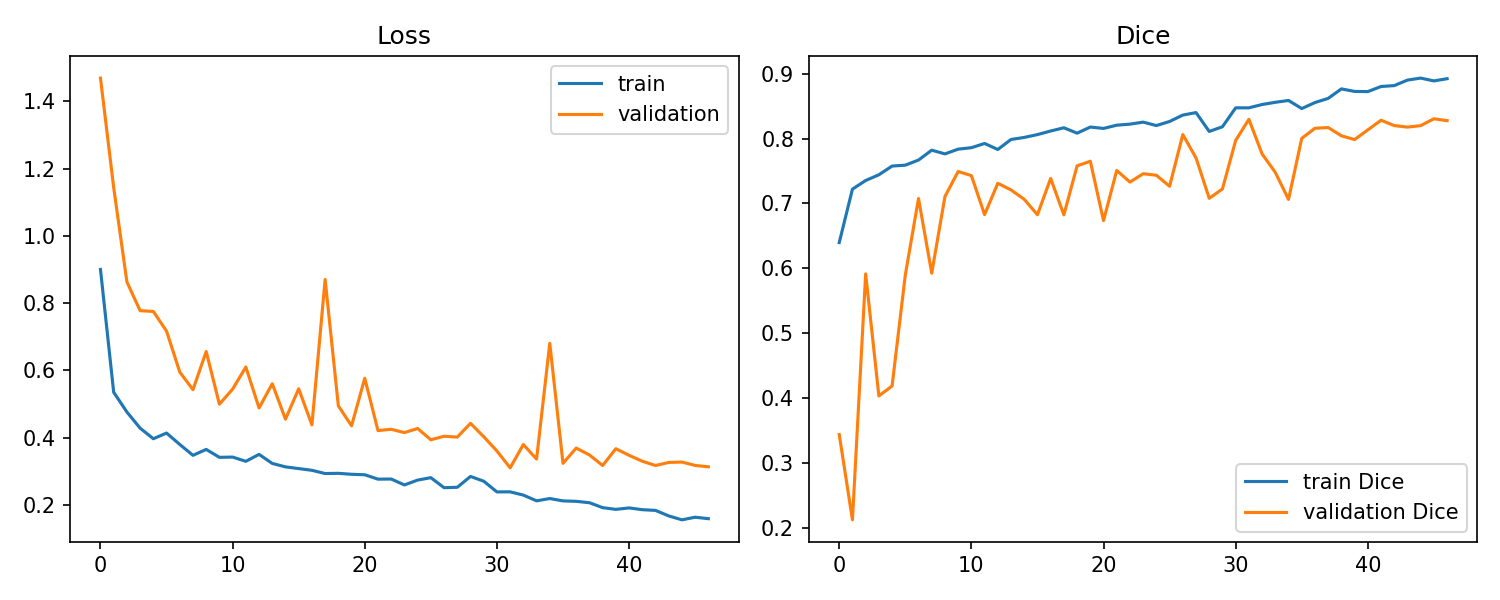

In [5]:
## 4. Inspect real test metrics

import json
from IPython.display import display, Image as IPyImage
print(Path(OUT_DIR,"test_metrics.json").read_text())
display(IPyImage(filename=str(Path(OUT_DIR,"training_history.png"))))

In [6]:
## 5. Download model and evidence

## 6. Next steps on your computer
# 1. Put `tumor_unet.keras` in the project's `models/` folder.
# 2. From project root run `docker compose up --build`.
# 3. Confirm `http://localhost:8000/health` says `"status":"ok"`.
# 4. In MATLAB run `addpath(fullfile(pwd,"matlab")); MedicalImageToolbox`.
# 5. Test API health, load a real MRI slice, run Keras segmentation, save the overlay, and record actual results.

W0000 00:00:1793535361.191448   57875 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
{
  "model": "/content/model_output/tumor_unet.keras",
  "test_samples_exported": 457,
  "threshold": 0.5,
  "image_size": 256,
  "mean_dice_exported_samples": 0.7343613520561213,
  "mean_iou_exported_samples": 0.7177417166737079,
  "note": "Means cover exported samples only if num-samples is less than the full test set."
}
Saved to /content/model_output/visual_evaluation


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Comparison images found: 457
001_TCGA_CS_5393_19990606_10_comparison.png


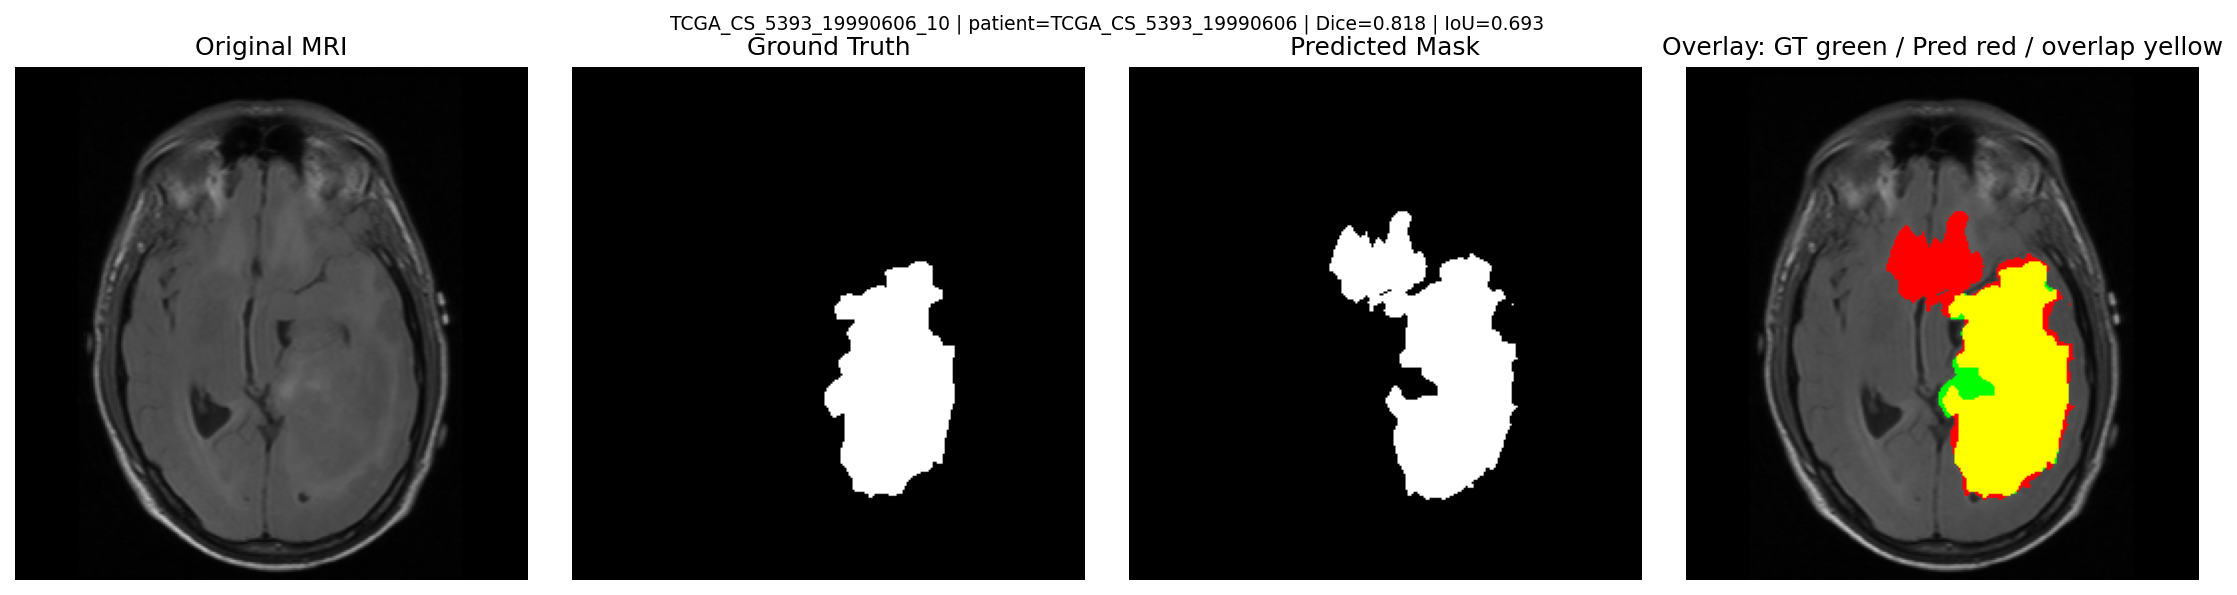

002_TCGA_CS_5393_19990606_11_comparison.png


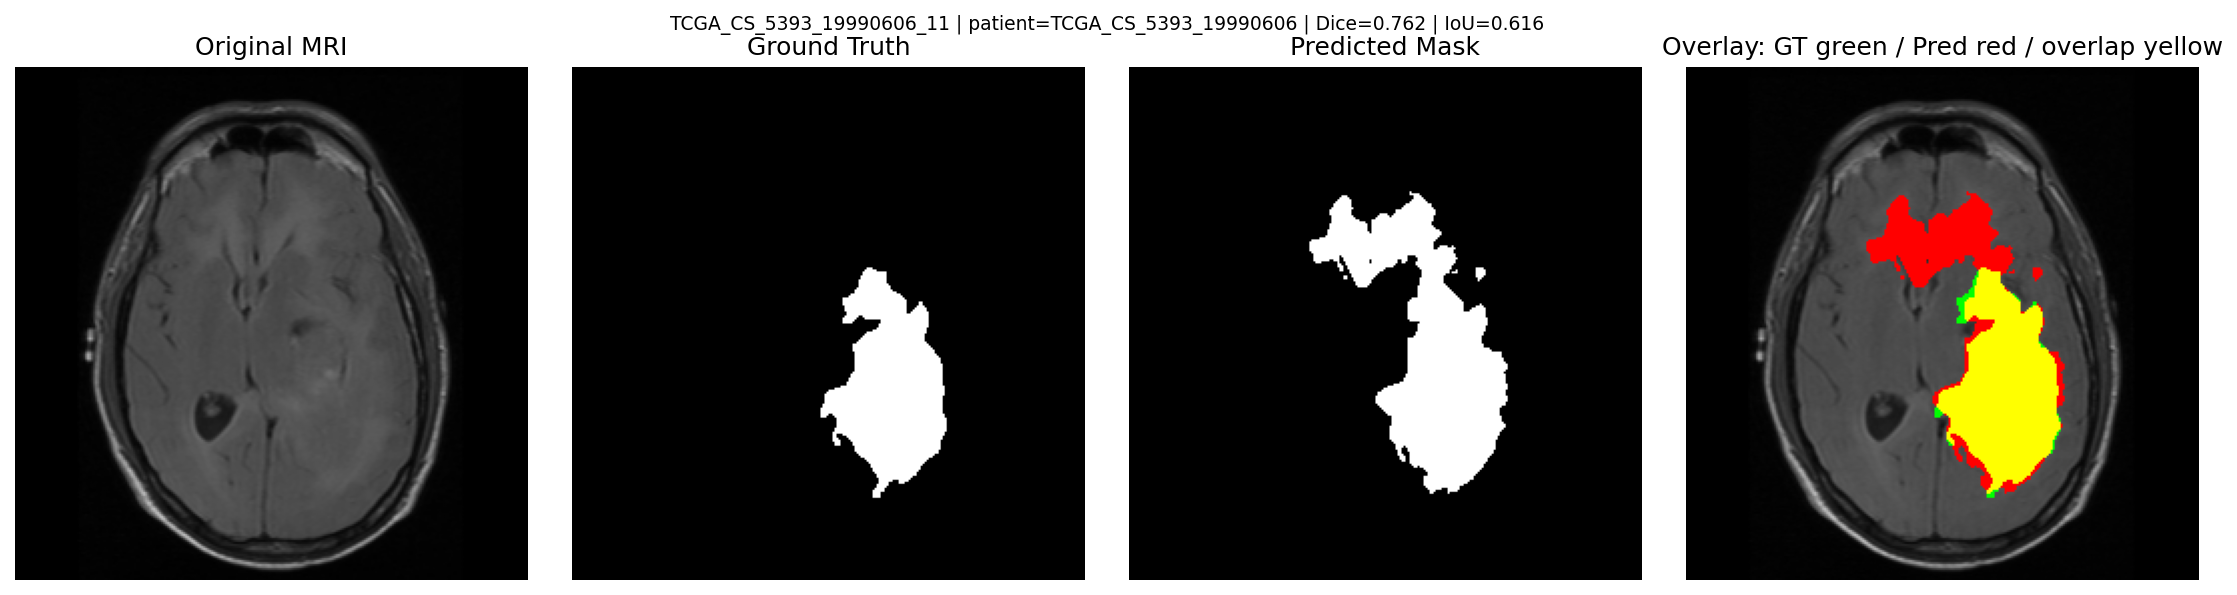

003_TCGA_CS_5393_19990606_12_comparison.png


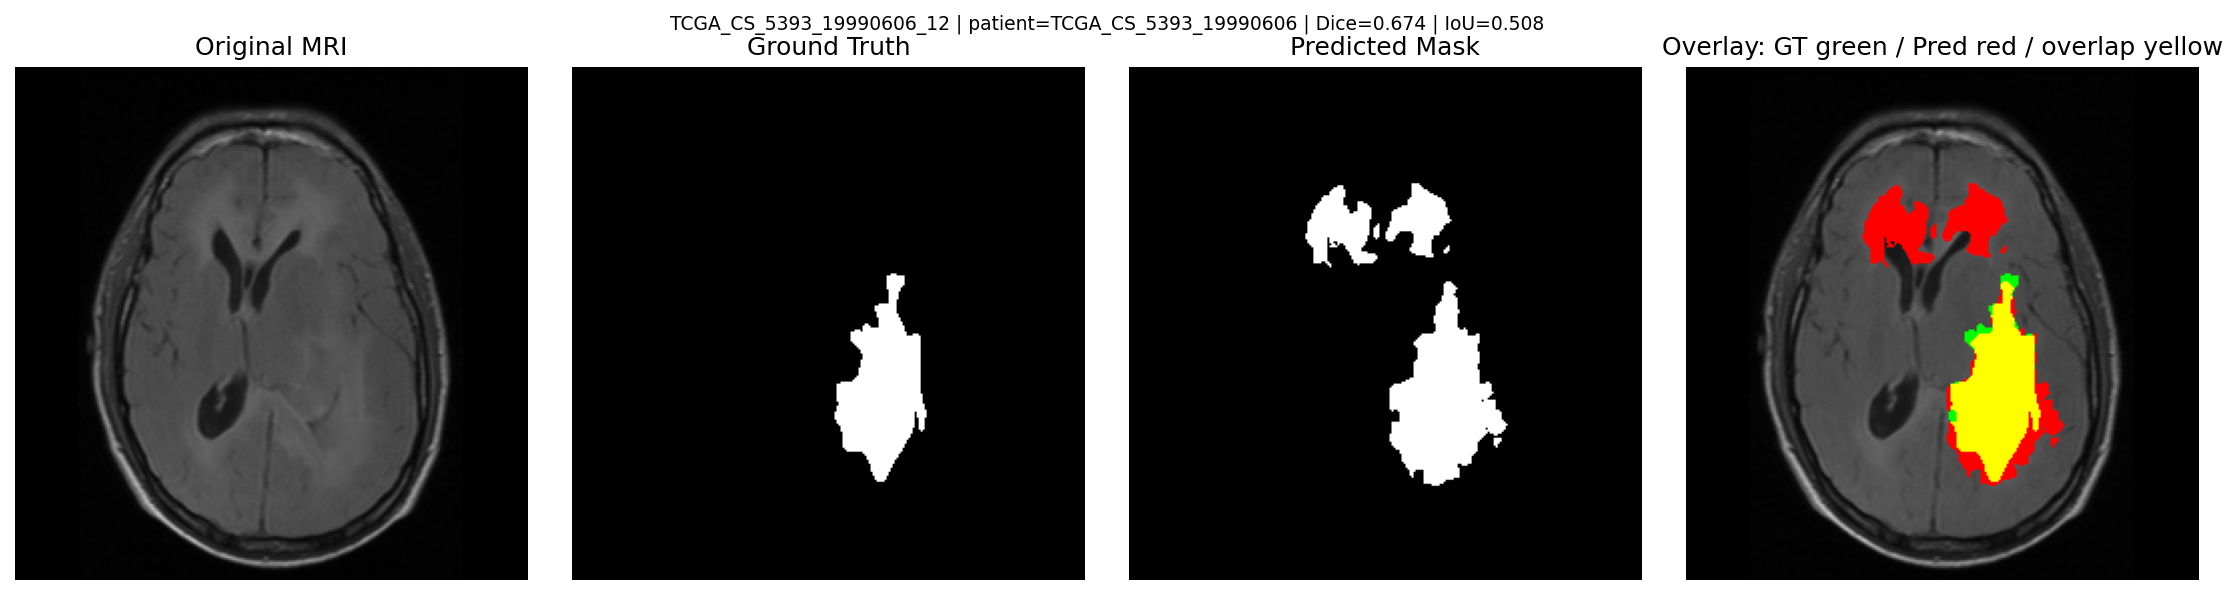

004_TCGA_CS_5393_19990606_13_comparison.png


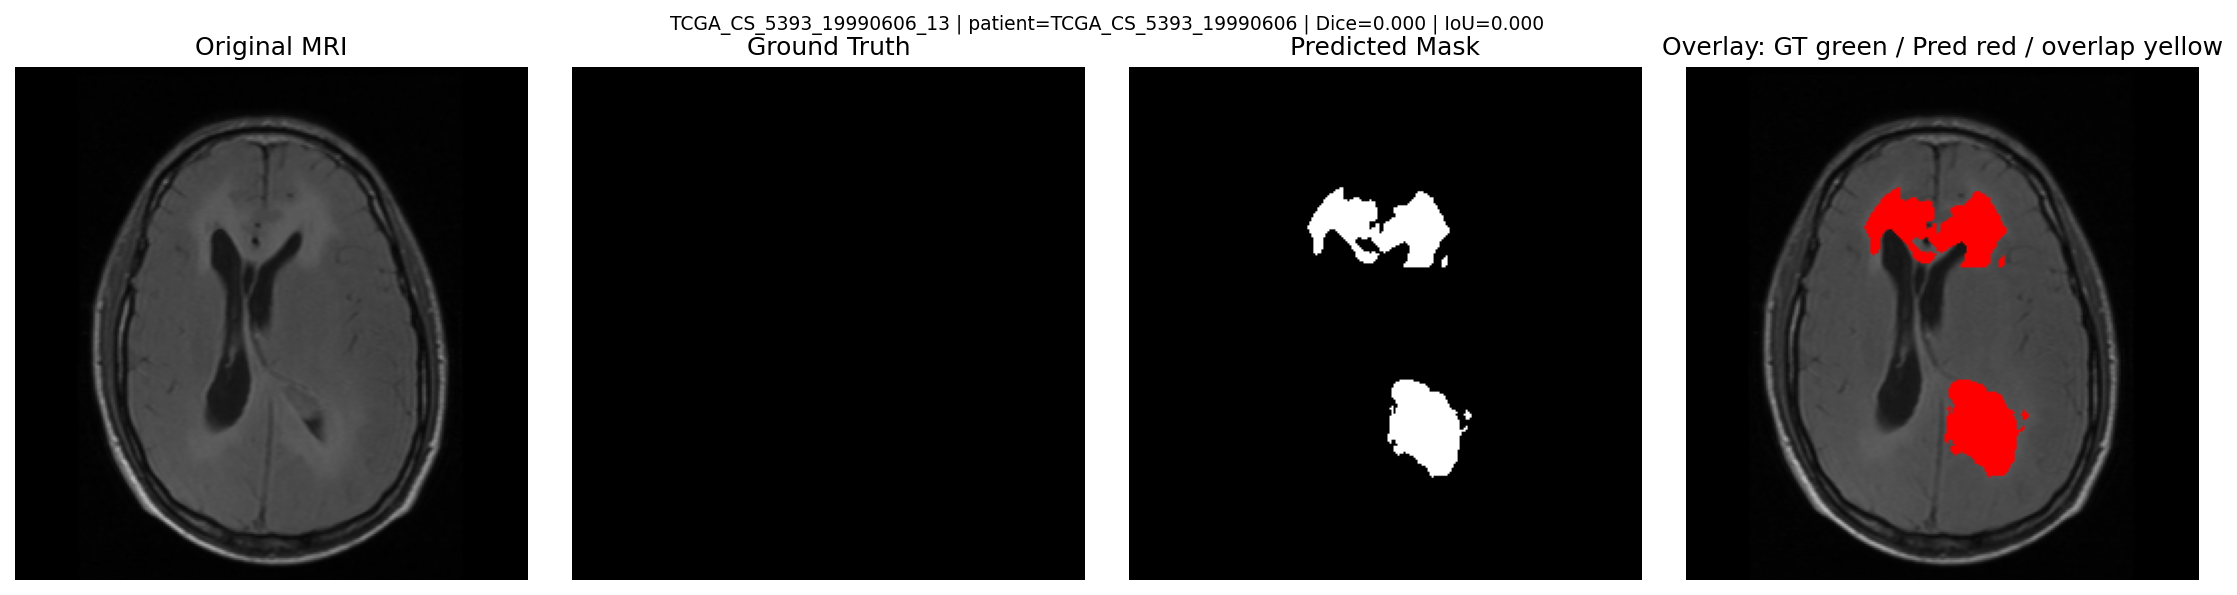

005_TCGA_CS_5393_19990606_14_comparison.png


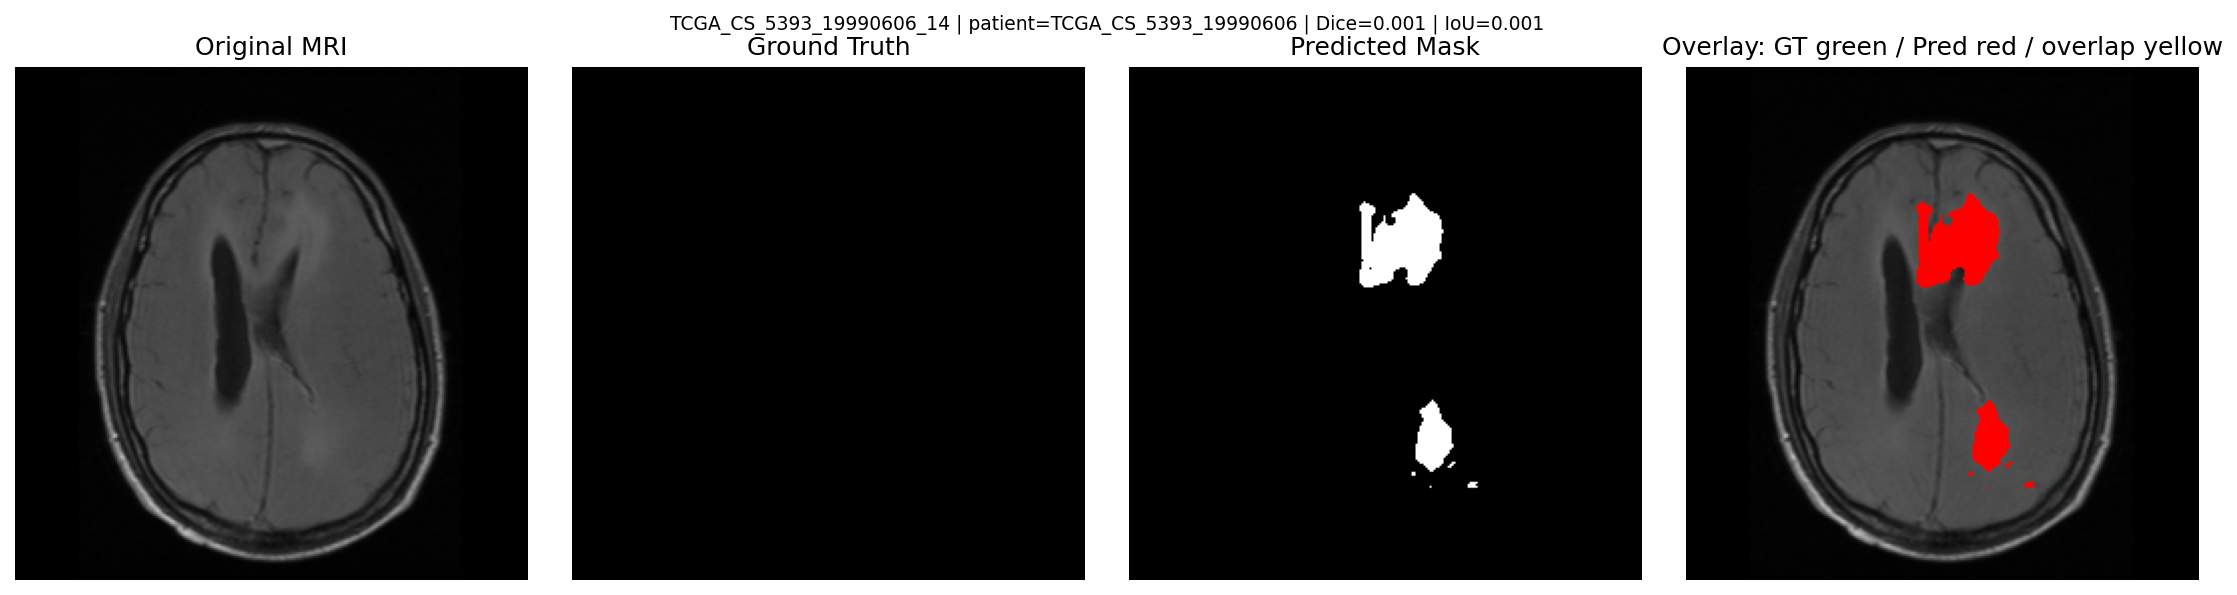

006_TCGA_CS_5393_19990606_15_comparison.png


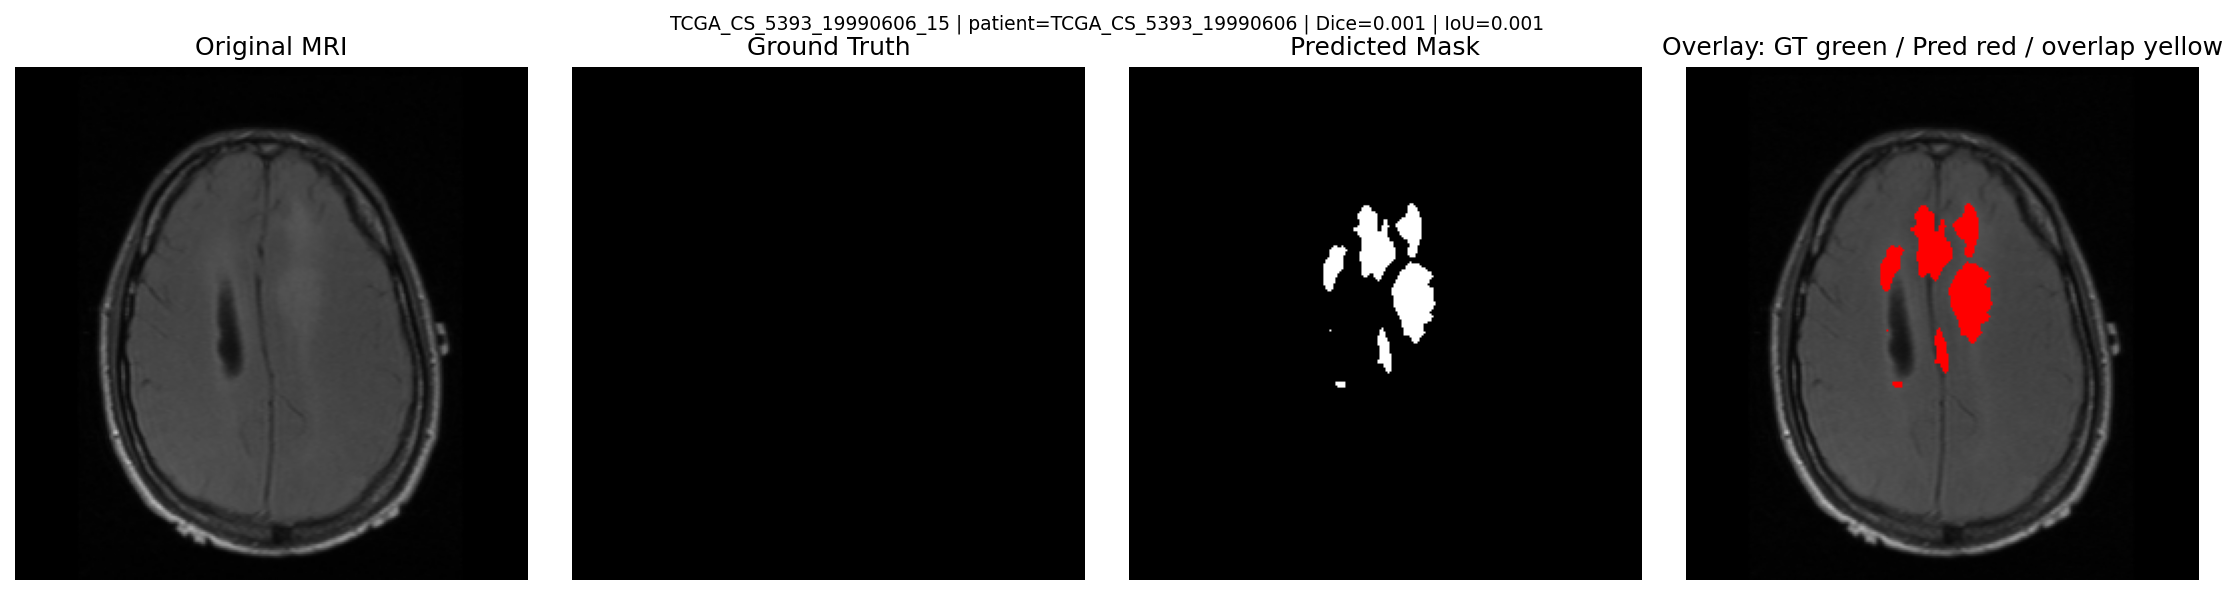

Created: /content/model_output/visual_evaluation.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
!python python/visual_evaluate.py \
  --data-dir "/content/data/lgg-mri-segmentation/kaggle_3m" \
  --model "/content/model_output/tumor_unet.keras" \
  --output-dir "/content/model_output/visual_evaluation" \
  --num-samples 0

from google.colab import files
for name in ["tumor_unet.keras","test_metrics.json","patient_split.json","training_history.png"]:
    p=Path(OUT_DIR,name)
    if p.exists(): files.download(str(p))
    else: print("Missing:",p)

# Display a few test-set comparisons and download all exported visual results.
from pathlib import Path
from IPython.display import display, Image as IPyImage
import shutil
from google.colab import files

VIS_DIR = Path(OUT_DIR) / "visual_evaluation"
comparison_files = sorted(VIS_DIR.glob("*_comparison.png"))
print(f"Comparison images found: {len(comparison_files)}")

# Show up to 6 comparisons directly in the notebook.
for img_path in comparison_files[:6]:
    print(img_path.name)
    display(IPyImage(filename=str(img_path)))

# Bundle all predictions, ground-truth masks, comparison panels and JSON metrics.
zip_base = str(Path(OUT_DIR) / "visual_evaluation")
zip_path = shutil.make_archive(zip_base, "zip", root_dir=str(VIS_DIR))
print("Created:", zip_path)
files.download(zip_path)